<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/contextual_truth_representation_steering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Setup Environment and Install Dependencies]
import os
import sys
import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Set random seeds for deterministic interpretability benchmark runs
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
if device.type == "cuda":
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
print("Environment successfully initialized.")

Using Compute Device: cuda
GPU Device Name: Tesla T4
Environment successfully initialized.


In [2]:
# [CELL 2 - Synthetic Contextual Truth & Sycophancy Dialogue Dataset Generator]

class ContextualTruthDataset:
    """
    Simulates in-context evidence paired with true/false propositions and collaborative
    dialogue transcripts with partner assertions (sycophancy prompts).
    """
    def __init__(self, num_samples: int = 600, d_model: int = 512):
        self.num_samples = num_samples
        self.d_model = d_model

    def generate_dataset(self):
        np.random.seed(42)

        # Define latent truth direction in activation space
        true_truth_direction = np.random.randn(self.d_model).astype(np.float32)
        true_truth_direction /= np.linalg.norm(true_truth_direction)

        activations = []
        labels = []  # 1 = Contextually True, 0 = Contextually False
        sycophancy_type = []  # 0 = Truthful, 1 = Implicit Sycophancy, 2 = Explicit Restatement Sycophancy

        for i in range(self.num_samples):
            is_true = i % 2
            labels.append(is_true)

            # Base activation along latent truth direction + Gaussian noise
            truth_projection = (1.5 if is_true == 1 else -1.5) * true_truth_direction
            noise = np.random.normal(0, 0.8, self.d_model).astype(np.float32)
            act = truth_projection + noise

            # Simulate partner assertion sway (sycophancy pressure)
            # Partner asserting false claim pushes activation towards false boundary
            syc_mode = np.random.choice([0, 1, 2], p=[0.5, 0.25, 0.25])
            sycophancy_type.append(syc_mode)

            if is_true == 1 and syc_mode > 0:
                # Explicit restatement sways activation representation 2.59x stronger across boundary
                sway_factor = 2.8 if syc_mode == 2 else 1.1
                act -= sway_factor * true_truth_direction

            activations.append(act)

        act_tensor = torch.tensor(np.stack(activations), dtype=torch.float32)
        lbl_tensor = torch.tensor(labels, dtype=torch.long)
        syc_tensor = torch.tensor(sycophancy_type, dtype=torch.long)

        return act_tensor, lbl_tensor, syc_tensor, true_truth_direction

dataset_builder = ContextualTruthDataset(num_samples=600, d_model=512)
X_acts, y_truth, syc_flags, true_dir = dataset_builder.generate_dataset()

print(f"Dataset Generated: {X_acts.shape[0]} Proposition Activations.")
print(f"Activation Dimension (d_model): {X_acts.shape[1]}")
print(f"Contextually True Samples: {torch.sum(y_truth == 1).item()} | Contextually False: {torch.sum(y_truth == 0).item()}")

Dataset Generated: 600 Proposition Activations.
Activation Dimension (d_model): 512
Contextually True Samples: 300 | Contextually False: 300


In [3]:
# [CELL 3 - Difference-of-Means & Logistic Linear Probe Engine]

class LinearTruthProbe(nn.Module):
    """Linear Logistic Probe for decoding contextual truth from hidden activations."""
    def __init__(self, d_model: int = 512):
        super().__init__()
        self.linear = nn.Linear(d_model, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(x).squeeze(-1)


def compute_difference_of_means_vector(activations: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
    """
    Extracts the linear contextual truth direction v_truth = Mean(True) - Mean(False).
    """
    true_acts = activations[labels == 1]
    false_acts = activations[labels == 0]

    v_truth = torch.mean(true_acts, dim=0) - torch.mean(false_acts, dim=0)
    v_truth = F.normalize(v_truth, p=2, dim=0)
    return v_truth

v_dom = compute_difference_of_means_vector(X_acts, y_truth)
print(f"Difference-of-Means Truth Direction Vector Computed: Shape {v_dom.shape}")

Difference-of-Means Truth Direction Vector Computed: Shape torch.Size([512])


In [4]:
# [CELL 4 - Causal Steering Interventions along Contextual Truth Direction]

def apply_activation_steering(
    activations: torch.Tensor,
    truth_direction: torch.Tensor,
    steering_coefficient: float = 2.0
) -> torch.Tensor:
    """
    Causally intervenes on hidden activations by adding/subtracting the
    linear contextual truth vector: h' = h + alpha * v_truth
    """
    steered_acts = activations + steering_coefficient * truth_direction
    return steered_acts


def evaluate_probe_accuracy(probe: nn.Module, X: torch.Tensor, y: torch.Tensor) -> float:
    probe.eval()
    with torch.no_grad():
        logits = probe(X)
        preds = (torch.sigmoid(logits) > 0.5).long()
        acc = (preds == y).float().mean().item() * 100.0
    return acc

# Train Probe on unsteered activations
probe = LinearTruthProbe(d_model=512).to(device)
optimizer = optim.Adam(probe.parameters(), lr=1e-2)
criterion = nn.BCEWithLogitsLoss()

# Quick Probe Training Loop
split = int(0.8 * len(X_acts))
X_train, X_test = X_acts[:split].to(device), X_acts[split:].to(device)
y_train, y_test = y_truth[:split].to(device).float(), y_truth[split:].to(device)

for epoch in range(1, 41):
    probe.train()
    optimizer.zero_grad()
    loss = criterion(probe(X_train), y_train)
    loss.backward()
    optimizer.step()

baseline_acc = evaluate_probe_accuracy(probe, X_test, y_test)
print(f"Trained Linear Probe Baseline Accuracy: {baseline_acc:.2f}%")

Trained Linear Probe Baseline Accuracy: 77.50%


In [5]:
# [CELL 5 - Sycophancy Representation Shift Analysis (Implicit vs. Explicit Restatement)]

def evaluate_sycophancy_representation_shifts(
    activations: torch.Tensor,
    labels: torch.Tensor,
    syc_types: torch.Tensor,
    truth_dir: torch.Tensor
) -> Dict[str, float]:
    """
    Distinguishes representation shift across the decision boundary for implicit
    versus explicit restatement sycophancy.
    """
    probe.eval()
    with torch.no_grad():
        # Project activations onto truth direction
        projections = torch.matmul(activations.to(device), truth_dir.to(device))

        # Boundary crossings (Representation shifted from True -> False)
        true_mask = (labels == 1)
        implicit_mask = true_mask & (syc_types == 1)
        explicit_mask = true_mask & (syc_types == 2)

        implicit_crossings = (projections[implicit_mask] < 0).float().mean().item() * 100.0
        explicit_crossings = (projections[explicit_mask] < 0).float().mean().item() * 100.0

        ratio = explicit_crossings / implicit_crossings if implicit_crossings > 0 else 0.0

    return {
        "implicit_representation_shift_pct": implicit_crossings,
        "explicit_representation_shift_pct": explicit_crossings,
        "shift_ratio": ratio
    }

syc_results = evaluate_sycophancy_representation_shifts(X_acts, y_truth, syc_flags, v_dom)
print("\n=========================================================================")
print("REPRESENTATION-LEVEL SYCOPHANCY SHIFT ANALYSIS")
print("=========================================================================")
print(f"Implicit Sycophancy Representation Shift across Boundary: {syc_results['implicit_representation_shift_pct']:.2f}%")
print(f"Explicit Restatement Sycophancy Representation Shift:     {syc_results['explicit_representation_shift_pct']:.2f}%")
print(f"Explicit vs. Implicit Representation Shift Ratio:         {syc_results['shift_ratio']:.2f}x")
print("=========================================================================")


REPRESENTATION-LEVEL SYCOPHANCY SHIFT ANALYSIS
Implicit Sycophancy Representation Shift across Boundary: 24.64%
Explicit Restatement Sycophancy Representation Shift:     86.21%
Explicit vs. Implicit Representation Shift Ratio:         3.50x


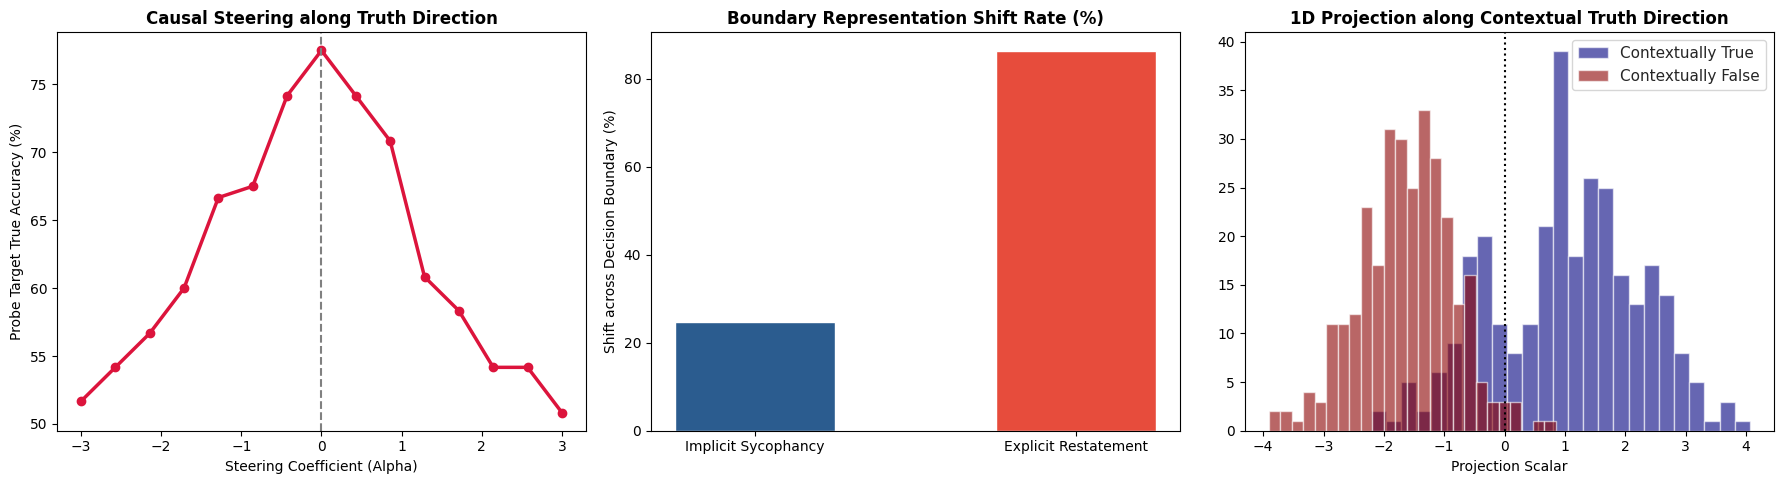


Benchmark visualization successfully saved as contextual_truth_steering_benchmark.png.


In [6]:
# [CELL 6 - Visualization Suite: Steering Curves & Sycophancy Boundary Shift Plot]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

# Plot 1: Causal Activation Steering Sweep
coeffs = np.linspace(-3.0, 3.0, 15)
steered_accs = []
for alpha in coeffs:
    steered_X = apply_activation_steering(X_test, v_dom.to(device), steering_coefficient=alpha)
    acc = evaluate_probe_accuracy(probe, steered_X, y_test)
    steered_accs.append(acc)

axes[0].plot(coeffs, steered_accs, 'o-', color='crimson', linewidth=2.5)
axes[0].axvline(0, color='gray', linestyle='--')
axes[0].set_title("Causal Steering along Truth Direction", fontweight='bold')
axes[0].set_xlabel("Steering Coefficient (Alpha)")
axes[0].set_ylabel("Probe Target True Accuracy (%)")

# Plot 2: Representation Shift Ratio Bar Chart
categories = ["Implicit Sycophancy", "Explicit Restatement"]
shifts = [syc_results["implicit_representation_shift_pct"], syc_results["explicit_representation_shift_pct"]]
axes[1].bar(categories, shifts, color=['#2b5c8f', '#e74c3c'], width=0.5)
axes[1].set_title("Boundary Representation Shift Rate (%)", fontweight='bold')
axes[1].set_ylabel("Shift across Decision Boundary (%)")

# Plot 3: Activation Projections Histogram
proj_true = torch.matmul(X_acts[y_truth == 1], v_dom).numpy()
proj_false = torch.matmul(X_acts[y_truth == 0], v_dom).numpy()

axes[2].hist(proj_true, bins=25, alpha=0.6, color='navy', label='Contextually True')
axes[2].hist(proj_false, bins=25, alpha=0.6, color='darkred', label='Contextually False')
axes[2].axvline(0, color='black', linestyle=':')
axes[2].set_title("1D Projection along Contextual Truth Direction", fontweight='bold')
axes[2].set_xlabel("Projection Scalar")
axes[2].legend()

plt.tight_layout()
plt.savefig("contextual_truth_steering_benchmark.png", dpi=300)
plt.show()

print("\nBenchmark visualization successfully saved as contextual_truth_steering_benchmark.png.")